# Analyse des résultats de CCF (Connect Component Finder)

## Représentation de l'effet de CCF sur le graph
Pour plus de lisibilité réalisation des représentations des graphiques sur la base des 500 premières connexions du jeu de donnée Google 

Chargement des librairies

In [2]:
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import networkx as nx
import gzip
import pandas as pd 
import os 
import numpy as np
import textwrap
# from Projet_bubble_graph import BubbleChart


# import plotly
# import plotly.express as px
# import pandas as pd

Chargement des données et transformation par l'agorithme CCF

In [ ]:
### ouverture du fichier d'origine avec les connexions existantes
with gzip.open('web-Google.txt.gz', 'rt') as f:
    data = f.read()
# Split des données sur la base du retour à la ligne
data = data.split("\n")
# retrait des premières lignes et dernière qui ne comporte pas d'information de connexion entre 2 éléments # moins 4 lignes
while data[0][0] == "#" :
  data = data[1:]
# Création du dataframe selon la taille souhaitée
df_avant = pd.DataFrame([x.split("\t") for x in data[0:501]], columns=["FromNodeId", "ToNodeId"])

### transformation
df = df_avant
cptnewpair = 1 # compteur pour vérifier la sortie du while
while cptnewpair >= 1 : 
    cptnewpair = 0
    
    # passage en bidirectionnel
    forward = df 
    reverse = df[["ToNodeId", "FromNodeId"]].rename(columns={"ToNodeId": "FromNodeId", "FromNodeId": "ToNodeId"})  
    df = pd.concat([forward, reverse]) 
    df = df.drop_duplicates().reset_index(drop=True)

    # Shuffle and sort
    dictionnaire = {}
    for l in range (df.shape[0]) : 
        cle = df.at[l, "FromNodeId"]
        valeur = df.at[l, "ToNodeId"]
        if cle not in dictionnaire :
            dictionnaire[cle] = [valeur]
        else:
            dictionnaire[cle].append(valeur)
    
    # traitement des noeuds
    df = pd.DataFrame(columns=("FromNodeId", "ToNodeId"))
    for key, values in dictionnaire.items() : 
        mini = key 
        for v in values : 
            if v < mini : 
                mini = v 
        if mini < key : 
            df.loc[len(df)] = [ key , mini ]
            for v in values : 
                if mini != v : 
                    cptnewpair += 1
                    df.loc[len(df)] = [v , mini ]

df_apres = df

Représentation des graphs avant/apres CCF

In [ ]:
def plot_network( data, titre, affichage) :
    # Transformation dataframe en networkx.classes.graph.Graph
    G = nx.from_pandas_edgelist(data, source='ToNodeId', target='FromNodeId')
    # Calcul des positions sur le graph
    pos = nx.spring_layout(G, k =0.16 , seed=10)  # 3, 10
    # ajout de l'info directement avec le noeud
    nx.set_node_attributes(G, pos, "pos") 
    
    degree_dict = dict(G.degree()) # Récupération du degré (nb de liens par noeud)
    
    node_colors = [degree_dict[node] for node in G.nodes()] # Création d'une liste de couleurs basée sur le degré
    labels = {node: str(node) for node, deg in degree_dict.items() if deg > affichage } # Labels seulement si degré > important
    
    # Plot avec couleur selon degre
    plt.figure(figsize=(8, 6))
    nx.draw_networkx_edges(G, pos, alpha=0.2)
    nodes = nx.draw_networkx_nodes(
        G, pos,
        node_size=  [ i*5 for i in list(degree_dict.values()) ], # list(d.values())
        node_color=node_colors,   # couleur = degré
        cmap=plt.cm.viridis       # choix de la colormap
    )
    nx.draw_networkx_labels(G, pos, labels = labels, font_size=8)   
    # Ajouter une barre de couleur
    plt.colorbar(nodes, label="Nombre de liens (degré)")
    plt.axis("off")
    # plt.show()
    plt.savefig(titre, dpi=300)

plot_network( df_avant , "500_google_AVANT_CCF-1.png" , 50 ) 
plot_network( df_apres , "500_google_APRES_CCF-1.png" , 20 ) 

## Représentation de l'effet de la parallélisation
Analyse faite sur 100 000 arrêtes intiales dans le fichier Google. Traitement des données en RDD avec Scala 

Chargement des données préalablement traitées, calcul du temps moyen par nombre de parallélisation et représentation

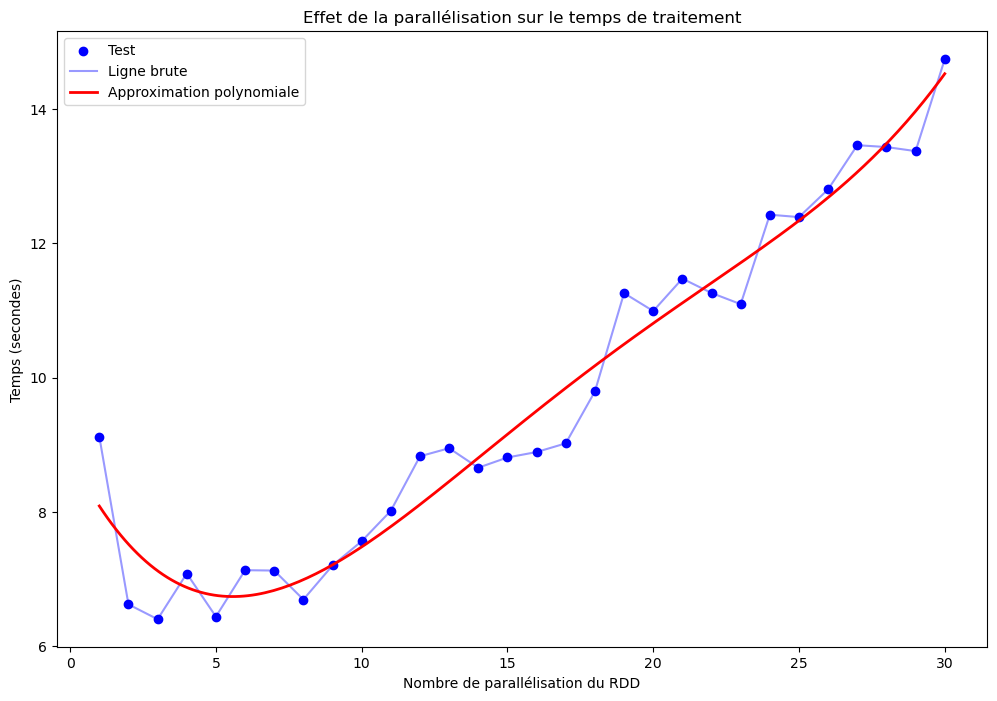

In [19]:
df = pd.read_csv("Projet_Scala_RDD_test_parall.csv")
df = df.groupby('nb_parellele')["temps"].mean()

x = df.index.values
y = df.values

plt.figure(figsize=(12,8))

# Points
plt.scatter(x, y, color="blue", label="Test")
# Ligne reliant directement les points
plt.plot(x, y, color="blue", alpha=0.4, linestyle='-', label="Ligne brute")
# Courbe polynomiale lissée
# Ajout d'un polynôme
coeffs = np.polyfit(x, y, deg=4)
poly = np.poly1d(coeffs)
# Création de points pour avoir une courbe lisse
x_smooth = np.linspace(x.min(), x.max(), 200)
y_smooth = poly(x_smooth)

plt.plot(x_smooth, y_smooth, color="red", linewidth=2, label="Approximation polynomiale")

# Mise en forme
plt.title("Effet de la parallélisation sur le temps de traitement")
plt.xlabel("Nombre de parallélisation du RDD")
plt.ylabel("Temps (secondes)")
plt.legend()
plt.grid(False)

plt.savefig("Effet_parallélisation", dpi=300)
plt.show()

## Représentation de la taille des groupes

In [1]:
# Charger les données
df = pd.read_csv("Projet_nb_connect_by_group_5M.csv", header=None)
df.columns = ["Node", "Effectif"]
df = df.sort_values("Effectif", ascending=False).reset_index(drop=True)

# Créer Effectif_transfo pour contrôler la taille visuelle des rectangles
df["Effectif_transfo"] = np.where(df["Effectif"] > 1000, 5000, df["Effectif"])

# Treemap : valeurs = Effectif_transfo pour la taille, couleur = dégradé selon Effectif réel
fig = px.treemap(
    df,
    path=['Node'],               
    values='Effectif_transfo',    
    color='Effectif',            # dégradé basé sur l'effectif réel
    hover_data=['Effectif'],     
    color_continuous_scale='Portland'  # dégradé de couleur
)

# Texte sur chaque rectangle = Effectif réel
fig.update_traces(
    texttemplate=df['Effectif'].astype(str),
    textinfo="text"
)

# Layout carré et lisible
fig.update_layout(
    width=1200,
    height=500,
    margin=dict(t=50, l=25, r=25, b=25)
)

fig.write_html("treemap_nodes.html")

# Affichage
fig.show()


# Comapraison des résultat

### Scala

In [2]:
df = pd.read_csv("Projet_Scala_Comp.csv")
# df['methode'] = df['methode'].str.replace('_', ' ', regex=False)
# Observation des tests fait
pd.crosstab(df['methode'], df['nb_init_aretes'])

nb_init_aretes,10,100,1000,10000,50000,100000,5105039
methode,,,,,,,
RDD_scala_iterate_avec_duplicat,3,3,3,3,3,3,0
RDD_scala_iterate_sans_duplicat,3,3,3,3,3,3,2
RDD_scala_iterate_sort_sans_duplicat,3,3,3,3,3,3,1
df_scala_iterate_avec_duplicat,1,1,1,1,0,1,0
df_scala_iterate_sans_duplicat,1,1,1,1,0,1,0
df_scala_iterate_sort_sans_duplicat,1,1,1,1,0,1,0


In [3]:
# Moyenne des différents tests
df = df.groupby(["methode","nb_init_aretes","nb_final_aretes","nb_groupes","nb_iter_CCF","nb_parellele"])["temps"].mean().reset_index()
df.head()

,methode,nb_init_aretes,nb_final_aretes,nb_groupes,nb_iter_CCF,nb_parellele,temps
0,RDD_scala_iterate_avec_duplicat,10,9,1,4,3,0.271943
1,RDD_scala_iterate_avec_duplicat,100,72,2,4,3,0.274727
2,RDD_scala_iterate_avec_duplicat,1000,419,11,4,3,0.233130
3,RDD_scala_iterate_avec_duplicat,10000,4129,59,8,3,0.990230
4,RDD_scala_iterate_avec_duplicat,50000,20945,218,8,3,3.050414


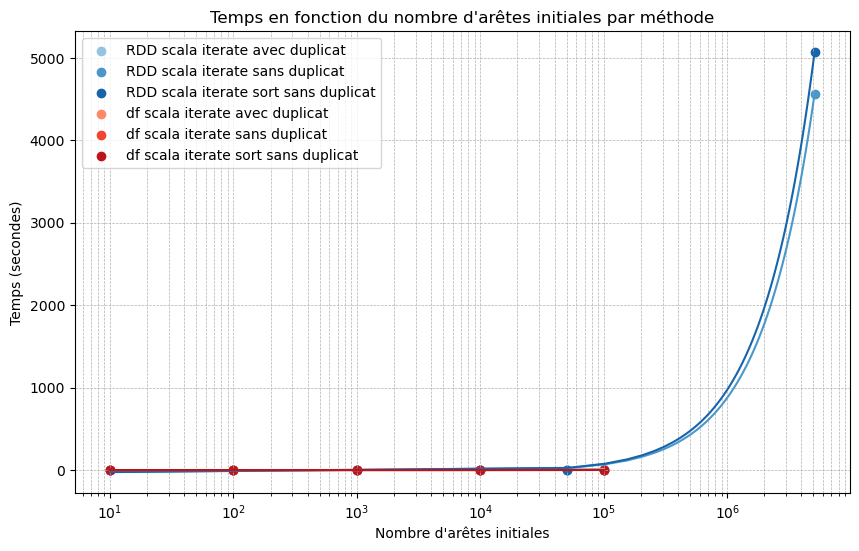

In [5]:
# Représentation graphique
# Filtrer les points avec nb_init_arretes <= 1_000_000
# df_filtered = df[df['nb_init_aretes'] <= 1000001]
df_filtered = df

# # Liste des méthodes
methodes = df_filtered['methode'].unique()
# couleurs = plt.cm.tab10.colors  # palette tab10
# couleur_map = {methode: couleurs[i % len(couleurs)] for i, methode in enumerate(methodes)}

# Créer une palette de couleurs chaudes et froides
couleurs_chaudes = plt.cm.Reds(np.linspace(0.4, 0.8, len([m for m in methodes if m.startswith("df_")])))
couleurs_froides = plt.cm.Blues(np.linspace(0.4, 0.8, len([m for m in methodes if m.startswith("RDD_")])))

# Construire un dictionnaire méthode → couleur
couleur_map = {}
i_chaud = 0
i_froid = 0
for m in methodes:
    if m.startswith("df"):
        couleur_map[m] = couleurs_chaudes[i_chaud]
        i_chaud += 1
    elif m.startswith("RDD"):
        couleur_map[m] = couleurs_froides[i_froid]
        i_froid += 1
    else:
        couleur_map[m] = "gray"  # pour sécurité si une autre méthode apparaît

plt.figure(figsize=(10, 6))

for methode in methodes:
    subset = df_filtered[df_filtered['methode'] == methode]

    label_affiche = methode.replace('_', ' ')
    
    # Tracer les points
    plt.scatter(subset['nb_init_aretes'], subset['temps'], label=label_affiche, color=couleur_map[methode])
    
    # Ajuster une droite (linéaire) : y = a*x + b
    coef = np.polyfit(subset['nb_init_aretes'], subset['temps'], 1)
    x_fit = np.linspace(subset['nb_init_aretes'].min(), subset['nb_init_aretes'].max(), 100)
    y_fit = np.polyval(coef, x_fit)
    plt.plot(x_fit, y_fit, color=couleur_map[methode])

plt.xscale('log')  # souvent pratique pour nb_init_arretes
plt.xlabel("Nombre d'arêtes initiales")
plt.ylabel("Temps (secondes)")
plt.title("Temps en fonction du nombre d'arêtes initiales par méthode")
plt.legend()
plt.grid(True, which="both", ls="--", lw=0.5)

plt.savefig("Projet_graph_Scala_temps_vs_aretes_5M.png", dpi=300, bbox_inches='tight')
plt.show()



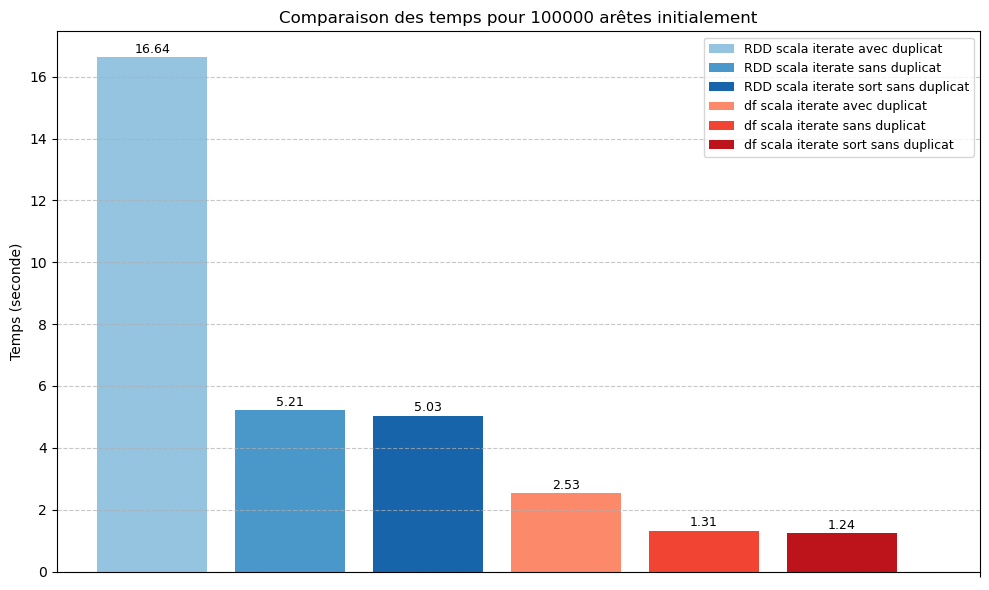

In [87]:
# Filtrer le DataFrame pour nb_init_arretes = 100_000
df_filtered = df[df['nb_init_aretes'] == 100000]

plt.figure(figsize=(10, 6))

bars = plt.bar(df_filtered['methode'], df_filtered['temps'], 
               color=[couleur_map[m] for m in df_filtered['methode']])

# Ajouter les valeurs au-dessus de chaque barre
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.05, f"{height:.2f}", 
             ha='center', va='bottom', fontsize=9)

# Modifier les ticks pour remplacer '_' par ' '
plt.xticks("")

plt.ylabel("Temps (seconde)")
plt.title("Comparaison des temps pour 100000 arêtes initialement")

# Légende dans un encadré en haut à droite
plt.legend(bars, [m.replace('_', ' ') for m in df_filtered['methode']],
           loc='upper right', bbox_to_anchor=(1.0, 1.0), frameon=True, fontsize=9)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Sauvegarder le plot
plt.savefig("Projet_graph_scala_barplot_temps_100000.png", dpi=300, bbox_inches='tight')

plt.show()


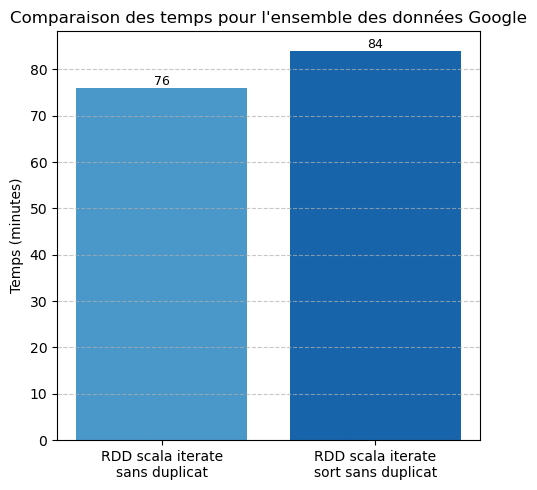

In [7]:
# Filtrer le DataFrame pour nb_init_arretes = 100_000
df_filtered = df[df['nb_init_aretes'] >= 2000000].copy() # copy sinon erreur pas une vraie copie
df_filtered["temps"] = (df_filtered["temps"] / 60).round().astype(int)

plt.figure(figsize=(5, 5))

bars = plt.bar(df_filtered['methode'], df_filtered['temps'], 
               color=[couleur_map[m] for m in df_filtered['methode']])

# Ajouter les valeurs au-dessus de chaque barre
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.05, f"{height:.0f}", 
             ha='center', va='bottom', fontsize=9)


labels = [textwrap.fill(m.replace('_', ' '), width=20) for m in df_filtered['methode']]

plt.xticks(
    ticks=range(len(df_filtered['methode'])),
    labels=labels,
    rotation=0,  # inutile de pencher si tu as des retours à la ligne
    ha='center'
)

# # Modifier les ticks pour remplacer '_' par ' '
# plt.xticks(ticks=range(len(df_filtered['methode'])),
#            labels=[m.replace('_', ' ') for m in df_filtered['methode']])
#            # rotation=45, ha='right')
plt.ylabel("Temps (minutes)")
plt.title("Comparaison des temps pour l'ensemble des données Google")

# Légende dans un encadré en haut à droite
# plt.legend(bars, [m.replace('_', ' ') for m in df_filtered['methode']],
#            loc='upper right', bbox_to_anchor=(1.0, 1.0), frameon=True, fontsize=9)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Sauvegarder le plot
plt.savefig("Projet_graph_scala_no_duplic_barplot_temps_all.png", dpi=300, bbox_inches='tight')

plt.show()

Python

In [8]:
df = pd.read_csv("Projet_Python_comp.csv")
# df['methode'] = df['methode'].str.replace('_', ' ', regex=False)
# Observation des tests fait
pd.crosstab(df['methode'], df['nb_init_aretes'])

nb_init_aretes,10,100,1000,10000,100000,500000,1000000,2000000,5105039
methode,,,,,,,,,
Spark_df_SQL,1,1,1,1,1,1,1,1,0
Spark_python_RDD_1,4,4,4,4,4,4,4,4,0
Spark_python_RDD_2,4,4,4,4,4,4,4,4,0
Spark_python_RDD_4,4,4,4,4,4,4,4,4,0
Spark_python_RDD_50,0,0,0,1,0,0,1,0,1
Spark_python_RDD_6,3,3,3,3,3,3,3,3,0
python_df,3,3,3,3,3,0,0,0,0


In [9]:
pd.crosstab(
    df['methode'],
    df['nb_init_aretes'],
    values=df['temps'],
    aggfunc='mean'
)


nb_init_aretes,10,100,1000,10000,100000,500000,1000000,2000000,5105039
methode,,,,,,,,,
Spark_df_SQL,15.131000,5.121000,4.806000,35.995000,45.106000,132.274000,240.30300,370.656000,NaN
Spark_python_RDD_1,2.174750,0.926750,1.357750,1.957250,7.271500,37.383750,72.83200,272.149000,NaN
Spark_python_RDD_2,1.099250,1.038250,1.548500,2.530750,6.435000,25.885500,48.60675,114.727500,NaN
Spark_python_RDD_4,1.748750,1.395750,2.183750,3.143000,6.397750,21.767000,42.16700,89.952000,NaN
Spark_python_RDD_50,NaN,NaN,NaN,172.425000,NaN,NaN,285.75400,NaN,722.986
Spark_python_RDD_6,2.871667,2.120333,2.953000,3.872333,7.225333,21.366667,39.84500,84.480667,NaN
python_df,0.051000,0.264000,3.252333,50.912333,2295.564000,NaN,NaN,NaN,NaN


In [22]:
# Exemple : tu as une liste de valeurs à garder
ma_liste = ["Spark_df_SQL", "Spark_python_RDD_6", "python_df","Spark_python_RDD_1"]
# Sélection des lignes où la colonne "ma_colonne" contient une valeur de ma_liste
df2 = df[df["methode"].isin(ma_liste)]

df2 = df2.groupby(["methode","nb_init_aretes","nb_final_aretes","nb_groupes","nb_iter_CCF","nb_parellele"])["temps"].mean().reset_index()
df2['methode'] = df2['methode'].str.replace('python_df', 'Python_dataframe', regex=False)
df2['methode'] = df2['methode'].str.replace('Spark_df_SQL', 'Spark_python_df_SQL', regex=False)
df2.head()

,methode,nb_init_aretes,nb_final_aretes,nb_groupes,nb_iter_CCF,nb_parellele,temps
0,Spark_python_df_SQL,10,9,1,2,1,15.131
1,Spark_python_df_SQL,100,72,2,2,1,5.121
2,Spark_python_df_SQL,1000,419,11,2,1,4.806
3,Spark_python_df_SQL,10000,4129,59,6,1,35.995
4,Spark_python_df_SQL,100000,39923,381,6,1,45.106


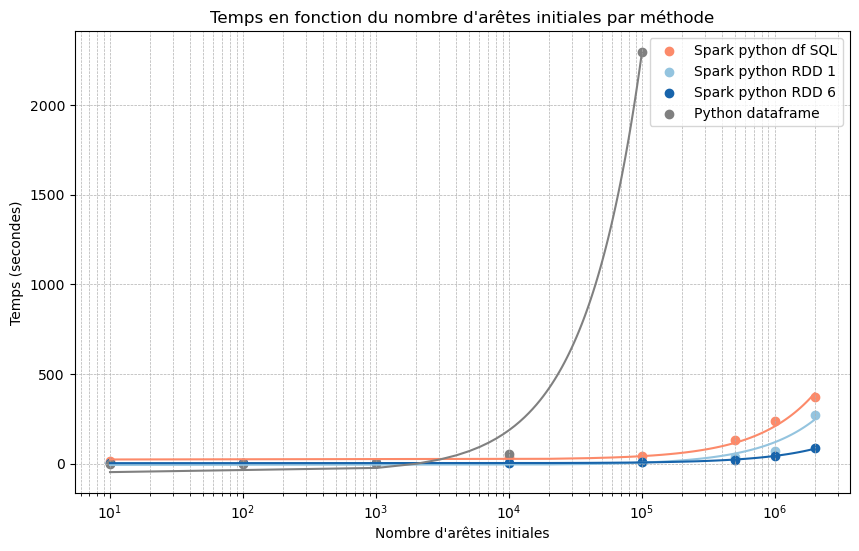

In [23]:
# Représentation graphique
# Filtrer les points avec nb_init_arretes <= 1_000_000
# df_filtered = df[df['nb_init_aretes'] <= 1000001]
df_filtered = df2

# # Liste des méthodes
methodes = df_filtered['methode'].unique()
# couleurs = plt.cm.tab10.colors  # palette tab10
# couleur_map = {methode: couleurs[i % len(couleurs)] for i, methode in enumerate(methodes)}

# Créer une palette de couleurs chaudes et froides
couleurs_chaudes = plt.cm.Reds(np.linspace(0.4, 0.8, len([m for m in methodes if m.startswith("Spark_python_df_")])))
couleurs_froides = plt.cm.Blues(np.linspace(0.4, 0.8, len([m for m in methodes if m.startswith("Spark_python_RDD_")])))

# Construire un dictionnaire méthode → couleur
couleur_map = {}
i_chaud = 0
i_froid = 0
for m in methodes:
    if m.startswith("Spark_python_df"):
        couleur_map[m] = couleurs_chaudes[i_chaud]
        i_chaud += 1
    elif m.startswith("Spark_python_RDD"):
        couleur_map[m] = couleurs_froides[i_froid]
        i_froid += 1
    else:
        couleur_map[m] = "gray"  # pour sécurité si une autre méthode apparaît

plt.figure(figsize=(10, 6))

for methode in methodes:
    subset = df_filtered[df_filtered['methode'] == methode]

    label_affiche = methode.replace('_', ' ')
    
    # Tracer les points
    plt.scatter(subset['nb_init_aretes'], subset['temps'], label=label_affiche, color=couleur_map[methode])
    
    # Ajuster une droite (linéaire) : y = a*x + b
    coef = np.polyfit(subset['nb_init_aretes'], subset['temps'], 1)
    x_fit = np.linspace(subset['nb_init_aretes'].min(), subset['nb_init_aretes'].max(), 100)
    y_fit = np.polyval(coef, x_fit)
    plt.plot(x_fit, y_fit, color=couleur_map[methode])

plt.xscale('log')  # souvent pratique pour nb_init_arretes
plt.xlabel("Nombre d'arêtes initiales")
plt.ylabel("Temps (secondes)")
plt.title("Temps en fonction du nombre d'arêtes initiales par méthode")
plt.legend()
plt.grid(True, which="both", ls="--", lw=0.5)

plt.savefig("Projet_graph_Python_temps_vs_aretes_2M.png", dpi=300, bbox_inches='tight')
plt.show()



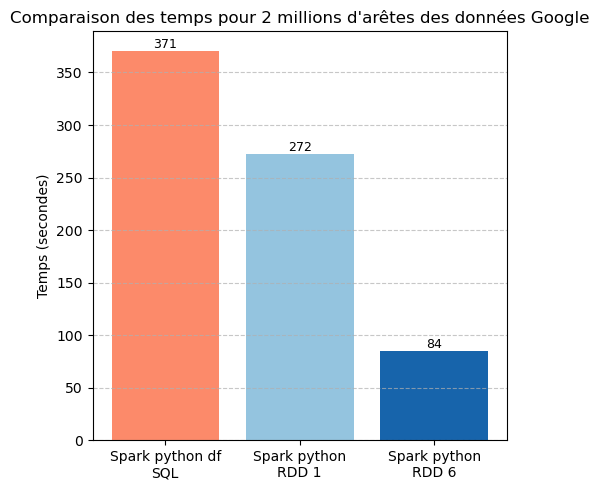

In [26]:
# Filtrer le DataFrame pour nb_init_arretes = 100_000
df_filtered = df2[df2['nb_init_aretes'] == 2000000].copy() # copy sinon erreur pas une vraie copie
# df_filtered["temps"] = (df_filtered["temps"] / 60).round().astype(int)

plt.figure(figsize=(5, 5))

bars = plt.bar(df_filtered['methode'], df_filtered['temps'], 
               color=[couleur_map[m] for m in df_filtered['methode']])

# Ajouter les valeurs au-dessus de chaque barre
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.05, f"{height:.0f}", 
             ha='center', va='bottom', fontsize=9)


labels = [textwrap.fill(m.replace('_', ' '), width=15) for m in df_filtered['methode']]

plt.xticks(
    ticks=range(len(df_filtered['methode'])),
    labels=labels,
    rotation=0,  # inutile de pencher si tu as des retours à la ligne
    ha='center'
)

# # Modifier les ticks pour remplacer '_' par ' '
# plt.xticks(ticks=range(len(df_filtered['methode'])),
#            labels=[m.replace('_', ' ') for m in df_filtered['methode']])
#            # rotation=45, ha='right')
plt.ylabel("Temps (secondes)")
plt.title("Comparaison des temps pour 2 millions d'arêtes des données Google")

# Légende dans un encadré en haut à droite
# plt.legend(bars, [m.replace('_', ' ') for m in df_filtered['methode']],
#            loc='upper right', bbox_to_anchor=(1.0, 1.0), frameon=True, fontsize=9)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Sauvegarder le plot
plt.savefig("Projet_graph_python_no_duplic_barplot_temps_2M.png", dpi=300, bbox_inches='tight')

plt.show()

# Comparaison machine et pipeline 

In [21]:
df = pd.read_csv("Synthese_test.csv")
df = df[ (df["Dataset"] == "Google") & (df["Langage"] == "Python")].reset_index()
df.head()

,index,Machine,Config,Pipeline,Langage,Structure,Algorithme,Dataset,Dataset_size,Temps_seconde,Temps_minutes
0,4,Rapide,Config_3,Pieline_2,Python,DF,Standard,Google,5105039,528.79,8.81
1,5,Rapide,Config_3,Pieline_2,Python,DF,Secondaire,Google,5105039,565.39,9.42
2,6,Rapide,Config_3,Pieline_2,Python,RDD,Standard,Google,5105039,1673.56,27.89
3,7,Rapide,Config_3,Pieline_2,Python,RDD,Secondaire,Google,5105039,1675.03,27.92
4,8,Lente,Config_2,Pieline_2,Python,DF,Standard,Google,5105039,240.05,4.00


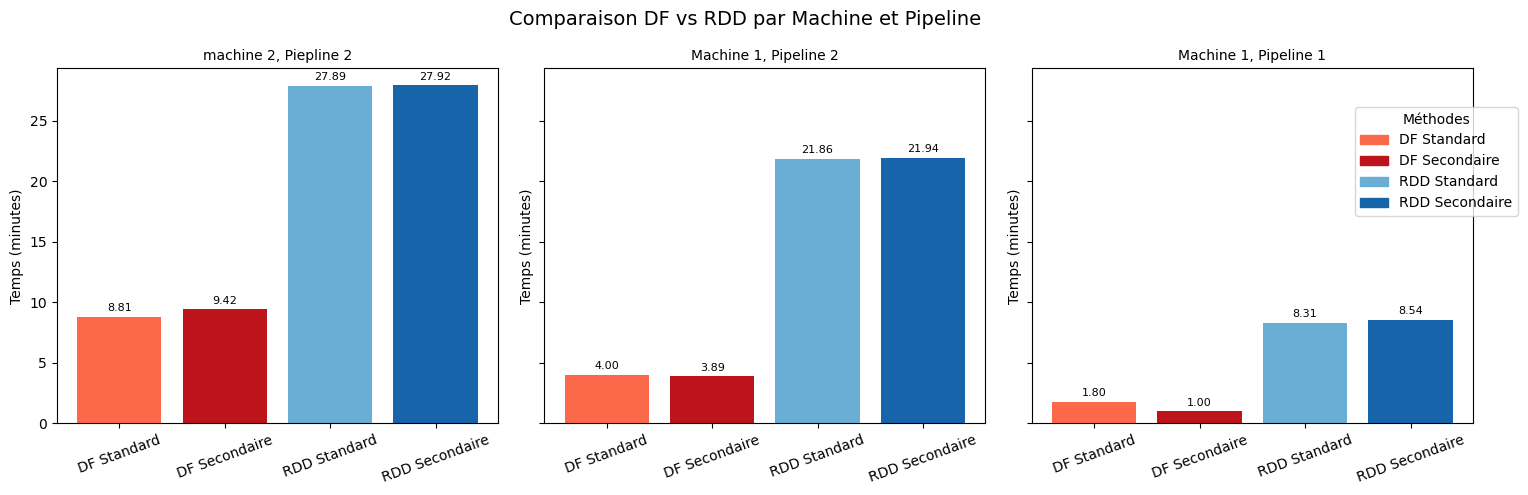

In [34]:
# -------------------------
# Colonnes dérivées
# -------------------------
df["Methode"] = df["Structure"].str.lower() + "_" + df["Algorithme"]
df["Test"] = df["Machine"] + "_" + df["Config"] + "_" + df["Pipeline"]

# -------------------------
# Définir couleurs
# -------------------------
methodes = ["df_Standard", "df_Secondaire", "rdd_Standard", "rdd_Secondaire"]

couleurs_chaudes = plt.cm.Reds(np.linspace(0.5, 0.8, 2))   # DF
couleurs_froides = plt.cm.Blues(np.linspace(0.5, 0.8, 2))  # RDD

couleur_map = {
    "df_Standard": couleurs_chaudes[0],
    "df_Secondaire": couleurs_chaudes[1],
    "rdd_Standard": couleurs_froides[0],
    "rdd_Secondaire": couleurs_froides[1],
}

# -------------------------
# Légendes personnalisées
# -------------------------
legend_labels = [
    "DF Standard",
    "DF Secondaire",
    "RDD Standard",
    "RDD Secondaire"
]

# -------------------------
# Création des sous-graphiques
# -------------------------
tests = df["Test"].unique()
tests_label = ["machine 2, Piepline 2", 
               "Machine 1, Pipeline 2" , 
               "Machine 1, Pipeline 1"] 

fig, axes = plt.subplots(1, len(tests), figsize=(15, 5), sharey=True)

if len(tests) == 1:
    axes = [axes]  # si un seul plot, convertir en liste

for ax, test, test_label in zip(axes, tests, tests_label):

    subset = df[df["Test"] == test]
    subset = subset.set_index("Methode").reindex(methodes)  # garder ordre
    
    bars = ax.bar(methodes, subset["Temps_minutes"], 
                  color=[couleur_map[m] for m in methodes])
    
    # Ajouter les valeurs au-dessus des barres
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, height + 0.3,
                f"{height:.2f}", ha="center", va="bottom", fontsize=8)
    
    ax.set_title(test_label, fontsize=10)
    ax.set_xticks(range(len(methodes)))
    ax.set_xticklabels(legend_labels, rotation=20)
    ax.set_ylabel("Temps (minutes)")

# Légende commune (labels personnalisés)
handles = [plt.Rectangle((0,0),1,1, color=couleur_map[m]) for m in methodes]
fig.legend(handles, legend_labels, title="Méthodes", bbox_to_anchor=(1.02, 0.8))

fig.suptitle("Comparaison DF vs RDD par Machine et Pipeline", fontsize=14)
plt.tight_layout()
plt.savefig("Projet_graph_python_comp_machine_pipeline.png", dpi=300, bbox_inches='tight')
plt.show()